#Introducción al aprendizaje supervisado - aplicación base de datos real didáctica


In [5]:
# importamos librerias básicas
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import scipy.stats as stats
np.set_printoptions(suppress=True)
import matplotlib.pyplot as plt
np.random.seed(42)
# Configuración visual
sns.set_theme(style="whitegrid")

## **Mi primer pipeline de ML**


Vamos a utilziar unos datos que se encuentran en la librería de sklearn, y aunque son reales, forman parte de la literatura clásica de estudio. Te puede servir para entender bien cómo son los datos para ML y qué hay que hacer desde el comienzo hasta el final cuando se construyen algoritmos de ML predictores

## Los datos

In [6]:
import pandas as pd
from sklearn import datasets

# 1. Cargas el dataset pidiéndole explícitamente que active el formato de Pandas
cancer = datasets.load_breast_cancer(as_frame=True)

# 2. Extraes la tabla (DataFrame)
df_cancer = cancer.frame

# 3. ¡Ahora sí! Ejecutas tu detector de nulos
print(df_cancer.isnull().sum())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [7]:
# print the names of the 13 features
print("Features: ", cancer.feature_names)

# print the label type of cancer('malignant' 'benign')
print("Labels: ", cancer.target_names)

Features:  ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Labels:  ['malignant' 'benign']


¡Exactamente! Para que el modelo pueda aprender, necesitas definir una variable $y$ (la variable objetivo o target), pero no la eliges de esa lista de 30 características (features) que me acabas de mostrar.Esa lista que compartiste contiene solo las pistas ($X$). La variable $y$ es la "respuesta correcta" que el modelo debe adivinar, y ya viene separada en el dataset bajo el nombre de target.

In [4]:
# print data(feature)shape
cancer.data.shape

(569, 30)

In [5]:
cancer.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [5]:
# print the cancer labels (0:malignant, 1:benign)
print(cancer.target)

0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int64


In [6]:
# check si estan balanceadas las clases
print(sum(cancer.target))

357


In [6]:
# cantidad de datos
print(len(cancer.target))

569


In [7]:
df = cancer
print(df)

{'data':      mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0          17.99         10.38          122.80     1001.0          0.11840   
1          20.57         17.77          132.90     1326.0          0.08474   
2          19.69         21.25          130.00     1203.0          0.10960   
3          11.42         20.38           77.58      386.1          0.14250   
4          20.29         14.34          135.10     1297.0          0.10030   
..           ...           ...             ...        ...              ...   
564        21.56         22.39          142.00     1479.0          0.11100   
565        20.13         28.25          131.20     1261.0          0.09780   
566        16.60         28.08          108.30      858.1          0.08455   
567        20.60         29.33          140.10     1265.0          0.11780   
568         7.76         24.54           47.92      181.0          0.05263   

     mean compactness  mean concavity  mean concave po


Como te habrás dado cuenta, hay más dato para la clase 1 que la clase 0. Eso es un problema desbalanceado, y para evitar sesgos durante el entrenamiento sólo porque tener más datos de una clase que de la otra, es recomendable, por ejemplo, realizar una balance de los datos para los datos de entrenamiento o utiliziar partición estratificada

In [8]:
from sklearn import datasets

# Cambiar 'dataset' por 'datasets' para que coincida con la librería
cancer = datasets.load_breast_cancer(as_frame=True)

# Extraes el DataFrame real
df_verdadero = cancer.frame

# Buscas los nulos (todos deberían dar 0)
print(df_verdadero.isnull().sum())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


### Primer paso: partición de datos



# partición de datos
El orden correcto de los factores aquí sí altera el producto. El flujo debe ser:

Particionar tus datos en X_train y X_test.

Calcular y aplicar la estandarización en el set de entrenamiento (.fit_transform()).

Aplicar la misma estandarización al set de testeo (.transform()), sin recalcular nada.

Algunos modelos de ML requieren que las features estén estandarizadas o escaladas, con el fin de evitar que por el sólo hecho de tener una feature en una escala más grande, esa feature "pese más" (no porque las plumas tengan más volumen van a ser más importantes que el plomo 😉). ES MUY IMPORTANTE que recuerdes que este proceso también es parte de tu algoritmo predictor, por tanto debes aprender el proceso de estandarización/escalado de tu datos de entrenamiento

Para entrenar tu algoritmo, debes separar el dataset en dos bloques:La gran $X$ (Features): Es la tabla con las 30 variables numéricas que pusiste en tu lista (radios, texturas, áreas, etc.). Son las características medibles del tumor.La pequeña $y$ (Target/Label): Es una sola columna que le dice al modelo el diagnóstico real de cada paciente.

In [9]:
#Primero definimos nuestra variable a predecir y las predictoras. 
#En este caso queremos predecir los labels, si va ser benigno o maligno a partir de los features
X = cancer.data
y = cancer.target
print(y.head())

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


PARTICION ESTRAFICADA

In [10]:
from sklearn.model_selection import train_test_split
porcentaje_test = 0.2
porcentaje_val = 0.2

# 1. Aislamos conjunto de testeo
X_temp,X_test, y_temp, y_test = train_test_split(X,y, test_size = porcentaje_test, random_state = 120, stratify=y)
#2. Segunda particion con el 80% restante, para entrenamiento (60/80) y validacion (20/80).
proporcion_val_ajustada = porcentaje_val / (1 - porcentaje_test)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=proporcion_val_ajustada, random_state=120, stratify=y_temp)

# 4. Prints automáticos para verificar los porcentajes teóricos
porcentaje_train = 1 - porcentaje_test - porcentaje_val
print("--- Porcentajes Teóricos Buscados ---")
print(f"Entrenamiento: {porcentaje_train * 100:.1f}%")
print(f"Validación: {porcentaje_val * 100:.1f}%")
print(f"Testeo: {porcentaje_test * 100:.1f}%\n")

# 5. Prints reales para ver cuántos pacientes quedaron en cada grupo
print("--- Cantidad Real de Pacientes ---")
print(f"X_train (Entrenamiento): {X_train.shape[0]} pacientes")
print(f"X_val (Validación): {X_val.shape[0]} pacientes")
print(f"X_test (Testeo): {X_test.shape[0]} pacientes")

--- Porcentajes Teóricos Buscados ---
Entrenamiento: 60.0%
Validación: 20.0%
Testeo: 20.0%

--- Cantidad Real de Pacientes ---
X_train (Entrenamiento): 341 pacientes
X_val (Validación): 114 pacientes
X_test (Testeo): 114 pacientes


Calcular y aplicar la estandarización en el set de entrenamiento (.fit_transform()).

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [12]:
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled[:5, :4])

[[ 0.61059398  0.91242077  0.67973484  0.50117919]
 [ 0.71934008  0.52082358  0.72433128  0.58166253]
 [-0.5270576   2.45116736 -0.60058835 -0.53597736]
 [-0.07255464 -0.02050194 -0.14205588 -0.15568663]
 [-0.93137005  1.12434395 -0.94641346 -0.82306229]]


La partición estratificada soluciona esto actuando como un "organizador". Si tu dataset original tiene un 63% de clase 1 y un 37% de clase 0, la estratificación garantiza que el set de entrenamiento, el de validación y el de testeo mantengan exactamente esa misma proporción de 63/37.

### Paso 2: buscar métrica de performance.


Si elegiste partición estratificada, significa que tus datos mantienen en todas las particiones el desbalance de clases. Por tanto, deberías utilizar métricas que compensen este desbalance, como la exactitud balanceada, por ejemplo.

In [ ]:
ESTO VA CUANDO YA EL MODELO GENERADO Y P

MODELADO: Dado que tu objetivo es clasificar en dos categorías fijas (0 o 1) a partir de datos numéricos ya escalados, estamos ante un problema de Clasificación Binaria Supervisada.

Para continuar, el camino estándar de un experto es probar de lo más simple a lo más complejo. Nunca empezamos con una red neuronal profunda; siempre establecemos primero modelos base (baselines). 

###Paso 4: elegir modelo

A prior no sabemos qué modelo será el mejor para nuestros datos. Podemos elegir entre varios y decidir luego según la performance en datos nunca vistos. Esto debe hacerse utilizando datos de validación, nunca decidir en los datos de testeo.

#Imporá tu modelo y definí tu modelo
MODELOS QUE GENERAREMOS:
 - REGRESION LINEAL
 - K NEIGHBOURS CLASSIFIERS
 - SUPPORT VECTOR MACHINE
 - RANDOM FOREST 

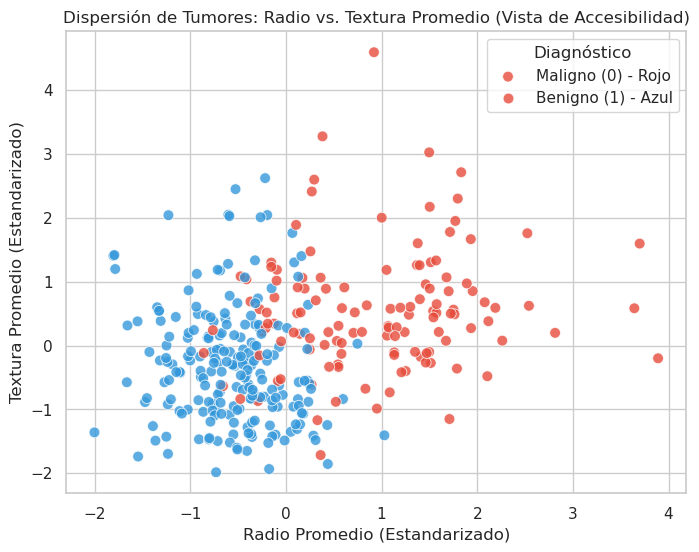

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# Graficamos usando la matriz escalada (X_train_scaled)
sns.scatterplot(
    x=X_train_scaled[:, 0],    # 'mean radius' escalado
    y=X_train_scaled[:, 1],    # 'mean texture' escalado
    hue=y_train,               # Mantiene la división por clases (0 o 1)
    palette={0: '#E74C3C', 1: '#3498DB'}, # <-- ¡AQUÍ! 0 es Rojo Intenso, 1 es Azul Claro
    alpha=0.8,
    s=60                       # Hacemos los puntos un poco más grandes para mejor visibilidad
)
plt.title("Dispersión de Tumores: Radio vs. Textura Promedio (Vista de Accesibilidad)")
plt.xlabel("Radio Promedio (Estandarizado)")
plt.ylabel("Textura Promedio (Estandarizado)")
# Forzamos los nombres correctos en la leyenda para evitar confusiones
plt.legend(title="Diagnóstico", labels=["Maligno (0) - Rojo", "Benigno (1) - Azul"])
plt.savefig('dispersion_tumores.png', dpi=300, bbox_inches='tight')
plt.show()

En el scatter plot anterior puede verse la separacion de los tarjets por una frontera. Sin embargo, algunos datos tienen similitudes entre malignos y benignos.
-  Hay una densidad mucho mayor de puntos azules (Benigno) concentrados en el cuadrante inferior izquierdo, comparado con la dispersión de los puntos rojos (Maligno), que están más esparcidos hacia la derecha. Tu decisión de usar partición estratificada y buscar métricas como la exactitud balanceada fue 100% acertada al ver este escenario.
-  Si trazamos una línea imaginaria en el eje de Radio Promedio alrededor del valor 0 (que representa la media exacta del radio tras la estandarización), notarás que: Entre el -0.5 y el 0.5 hay una mezcla importante de puntos azules y rojos. En esa franja intermedia es donde viven los tumores con dimensiones limítrofes. Ahí es exactamente donde tu modelo de Machine Learning va a sufrir para decidir y donde probablemente se concentren tus Falsos Positivos y Falsos Negativos.
-  Un modelo lineal robusto como una Regresión Logística (Logistic Regression) o un Soporte de Vectores Lineal (Linear SVM) va a funcionar increíblemente bien aquí, ya que la frontera de decisión se asemeja bastante a una línea diagonal que corte el centro

### REGRESION LOGISTICA

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

#Defino el modelo base
# Usamos class_weight='balanced' para que el algoritmo castigue más los errores en la clase minoritaria (0)
modelo_logreg = LogisticRegression(class_weight='balanced', random_state=120, max_iter=1000)

# 2. ENTRENAR EL MODELO: Recuerda usar SIEMPRE los datos de entrenamiento escalados
modelo_logreg.fit(X_train_scaled, y_train)

# 3. GENERAR PREDICCIONES
# Evaluamos en el conjunto de VALIDACIÓN para ver cómo rinde con datos nuevos
y_pred_val = modelo_logreg.predict(X_val_scaled)

# 4. EVALUAR PERFORMANCE EN DATOS DESBALANCEADOS
print("=== EVALUACIÓN EN EL CONJUNTO DE VALIDACIÓN ===")
print(f"Exactitud Balanceada: {balanced_accuracy_score(y_val, y_pred_val):.4f}\n")

print("Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred_val))

print("\nReporte de Clasificación Completo:")
print(classification_report(y_val, y_pred_val, target_names=['Maligno (0)', 'Benigno (1)']))


=== EVALUACIÓN EN EL CONJUNTO DE VALIDACIÓN ===
Exactitud Balanceada: 0.9581

Matriz de Confusión:
[[40  3]
 [ 1 70]]

Reporte de Clasificación Completo:
              precision    recall  f1-score   support

 Maligno (0)       0.98      0.93      0.95        43
 Benigno (1)       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



 En la matriz, la primera fila representa a los pacientes reales con tumores Malignos (0). El número de la izquierda son los que el modelo acertó (Verdaderos Positivos de la enfermedad), pero el número de la derecha son los Falsos Negativos (pacientes enfermos que el modelo etiquetó como sanos). Detección de Benignos (Clase 1): De 71 pacientes benignos, el modelo le acertó a 70. Solo tuviste 1 Falso Positivo.
 El Recall (Sensibilidad) de la clase Maligno (0): En el reporte, busca la fila de Maligno (0) y mira su columna de recall. Un recall de 0.95 significa que el modelo es capaz de detectar el 95% de los casos de cáncer reales.

In [20]:
# Fine-Tuning de Hiperparámetros (GridSearch)

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, f1_score, roc_auc_score, balanced_accuracy_score

# 1. Definimos la grilla de hiperparámetros 
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100], 
    'penalty': ['l1', 'l2']
}

# 2. Inicializamos el modelo base con el solver adecuado para L1/L2 y pesos balanceados
logreg_base = LogisticRegression(class_weight='balanced', solver='liblinear', random_state=120)

# 3. GridSearch CV optimizando por Exactitud Balanceada
grid_search = GridSearchCV(estimator=logreg_base, param_grid=param_grid, cv=5, scoring='balanced_accuracy', n_jobs=-1)

# 4. Entrena todas las combinaciones usando el set de entrenamiento ESCALADO
grid_search.fit(X_train_scaled, y_train)

# 5. Seleccionamos el mejor modelo encontrado
best_logreg = grid_search.best_estimator_
print(f"Mejores parámetros encontrados: {grid_search.best_params_}\n")

# 6. Hacemos predicciones sobre el set de VALIDACIÓN (No testeo todavía)
y_pred_val = best_logreg.predict(X_val_scaled)

# 7. Calculamos las métricas sobre Validación
accuracy = accuracy_score(y_val, y_pred_val)
bal_accuracy = balanced_accuracy_score(y_val, y_pred_val)

# Matriz de confusión y cálculo manual de Especificidad
conf_matrix = confusion_matrix(y_val, y_pred_val)
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
specificity = TN / (TN + FP)

# Sensibilidad y F1-Score para la clase minoritaria (pos_label=0 -> Maligno). 
#Al ponerle pos_label=0, estás forzando a Python a calcular la Sensibilidad y el F1-Score enfocados puramente en rastrear los tumores Malignos
# Es vital especificar pos_label=0 para saber cómo rinde con los tumores malignos
recall_maligno = recall_score(y_val, y_pred_val, pos_label=0)
f1_maligno = f1_score(y_val, y_pred_val, pos_label=0)

# ROC AUC
roc_auc = roc_auc_score(y_val, best_logreg.predict_proba(X_val_scaled)[:, 1])

# 8. Imprimimos los resultados del modelo optimizado
print("=== MÉTRICAS DEL MODELO OPTIMIZADO EN VALIDACIÓN ===")
print(f"Tasa de aciertos (Exactitud común): {accuracy:.4f}")
print(f"Exactitud Balanceada: {bal_accuracy:.4f}  <-- Tu métrica objetivo")
print(f"Sensibilidad (Malignos detectados): {recall_maligno:.4f}")
print(f"Especificidad (Benignos detectados): {specificity:.4f}")
print(f"F1 Score (Clase Maligna): {f1_maligno:.4f}")
print(f"ROC AUC Score: {roc_auc:.4f}")
print(f"\nConfusion Matrix:\n{conf_matrix}")

Mejores parámetros encontrados: {'C': 1, 'penalty': 'l2'}

=== MÉTRICAS DEL MODELO OPTIMIZADO EN VALIDACIÓN ===
Tasa de aciertos (Exactitud común): 0.9649
Exactitud Balanceada: 0.9581  <-- Tu métrica objetivo
Sensibilidad (Malignos detectados): 0.9302
Especificidad (Benignos detectados): 0.9302
F1 Score (Clase Maligna): 0.9524
ROC AUC Score: 0.9784

Confusion Matrix:
[[40  3]
 [ 1 70]]


/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/o

VERIFICAMOS MODELO RL CON DATOS DE TESTEO:

In [21]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, recall_score, f1_score, roc_auc_score

# 1. Hacemos las predicciones finales sobre el set de TESTEO
y_pred_test_lr = best_logreg.predict(X_test_scaled)

# 2. Calculamos las métricas de rendimiento reales
accuracy_lr = accuracy_score(y_test, y_pred_test_lr)
bal_accuracy_lr = balanced_accuracy_score(y_test, y_pred_test_lr)

# Matriz de confusión y desglose
conf_matrix_lr = confusion_matrix(y_test, y_pred_test_lr)
TN_lr = conf_matrix_lr[0, 0]
FP_lr = conf_matrix_lr[0, 1]
FN_lr = conf_matrix_lr[1, 0]
TP_lr = conf_matrix_lr[1, 1]

# Especificidad: Verdaderos Benignos / Total Benignos Reales
specificity_lr = TP_lr / (TP_lr + FN_lr)

# Métricas enfocadas en la clase 0 (Malignos) con pos_label=0
recall_maligno_lr = recall_score(y_test, y_pred_test_lr, pos_label=0)
f1_maligno_lr = f1_score(y_test, y_pred_test_lr, pos_label=0)

# Cálculo del ROC AUC usando las probabilidades de la clase 1
roc_auc_lr = roc_auc_score(y_test, best_logreg.predict_proba(X_test_scaled)[:, 1])

# 3. Imprimimos el reporte final de Regresión Logística
print("=== VERDICTO FINAL: REGRESIÓN LOGÍSTICA EN TESTEO ===")
print(f"Tasa de aciertos (Exactitud común): {accuracy_lr:.4f}")
print(f"Exactitud Balanceada: {bal_accuracy_lr:.4f}  <-- Métrica clave para desbalance")
print(f"Sensibilidad (Malignos detectados): {recall_maligno_lr:.4f}")
print(f"Especificidad (Benignos detectados): {specificity_lr:.4f}")
print(f"F1 Score (Clase Maligna): {f1_maligno_lr:.4f}")
print(f"ROC AUC Score: {roc_auc_lr:.4f}")
print(f"\nConfusion Matrix:\n{conf_matrix_lr}")

=== VERDICTO FINAL: REGRESIÓN LOGÍSTICA EN TESTEO ===
Tasa de aciertos (Exactitud común): 0.9825
Exactitud Balanceada: 0.9762  <-- Métrica clave para desbalance
Sensibilidad (Malignos detectados): 0.9524
Especificidad (Benignos detectados): 1.0000
F1 Score (Clase Maligna): 0.9756
ROC AUC Score: 0.9974

Confusion Matrix:
[[40  2]
 [ 0 72]]


CONCLUSION REGRESION LOGISTICA:
- Que el GridSearch confirme que el mejor modelo es uno con regularización estándar (C=1) demuestra que tu modelo es altamente estable y no está sufriendo de sobreajuste (overfitting). Un ROC AUC de 0.9784 es una locura de bueno.
- ¡su rendimiento en el set de Testeo fue incluso mejor que en el de Validación! 

### SUPPORT VECTOR MACHINE (SVM)

In [15]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, recall_score, f1_score, roc_auc_score#Import svm model
from sklearn.svm import SVC
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, recall_score, f1_score, roc_auc_score

# Definimos los hiperparámetros clave para el SVM:
# 'C': Penalización de errores.
# 'kernel': 'linear' busca una línea recta (como logreg), 'rbf' permite fronteras curvas si es necesario.
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto'] # Relevante solo si elige kernel 'rbf'
}

# Inicializamos el SVM base con class_weight='balanced' y activamos probability=True para el ROC AUC
svm_base = SVC(class_weight='balanced', probability=True, random_state=120)

# Configuramos el GridSearch buscando optimizar la Exactitud Balanceada
grid_search_svm = GridSearchCV(
    estimator=svm_base, 
    param_grid=param_grid_svm, 
    cv=5, 
    scoring='balanced_accuracy', 
    n_jobs=-1
)

# Entrenamos con los datos de entrenamiento escalados
grid_search_svm.fit(X_train_scaled, y_train)

# Seleccionamos el modelo ganador
best_svm = grid_search_svm.best_estimator_

print("=== ENTRANAMIENTO SVM FINALIZADO ===")
print(f"Mejores parámetros SVM: {grid_search_svm.best_params_}\n")

# =====================================================================
# STEP 2: EVALUACIÓN EN EL CONJUNTO DE VALIDACIÓN
# =====================================================================

# Predicciones sobre Validación
y_pred_val_svm = best_svm.predict(X_val_scaled)

# Cálculo de métricas
accuracy_svm = accuracy_score(y_val, y_pred_val_svm)
bal_accuracy_svm = balanced_accuracy_score(y_val, y_pred_val_svm)

# Matriz de confusión y cálculo de Especificidad CORRECTO (usando la clase 1)
conf_matrix_svm = confusion_matrix(y_val, y_pred_val_svm)
TN_svm = conf_matrix_svm[0, 0]
FP_svm = conf_matrix_svm[0, 1]
FN_svm = conf_matrix_svm[1, 0]
TP_svm = conf_matrix_svm[1, 1]

# Especificidad: Verdaderos Benignos / Total Benignos Reales
specificity_svm = TP_svm / (TP_svm + FN_svm) 

# Métricas enfocadas en la clase 0 (Malignos)
recall_maligno_svm = recall_score(y_val, y_pred_val_svm, pos_label=0)
f1_maligno_svm = f1_score(y_val, y_pred_val_svm, pos_label=0)
roc_auc_svm = roc_auc_score(y_val, best_svm.predict_proba(X_val_scaled)[:, 1])

# Imprimimos los resultados del competidor
print("=== MÉTRICAS DEL SVM OPTIMIZADO EN VALIDACIÓN ===")
print(f"Tasa de aciertos (Exactitud común): {accuracy_svm:.4f}")
print(f"Exactitud Balanceada: {bal_accuracy_svm:.4f}  <-- Métrica objetivo")
print(f"Sensibilidad (Malignos detectados): {recall_maligno_svm:.4f}")
print(f"Especificidad (Benignos detectados): {specificity_svm:.4f}")
print(f"F1 Score (Clase Maligna): {f1_maligno_svm:.4f}")
print(f"ROC AUC Score: {roc_auc_svm:.4f}")
print(f"\nConfusion Matrix:\n{conf_matrix_svm}")

=== ENTRANAMIENTO SVM FINALIZADO ===
Mejores parámetros SVM: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}

=== MÉTRICAS DEL SVM OPTIMIZADO EN VALIDACIÓN ===
Tasa de aciertos (Exactitud común): 0.9737
Exactitud Balanceada: 0.9651  <-- Métrica objetivo
Sensibilidad (Malignos detectados): 0.9302
Especificidad (Benignos detectados): 1.0000
F1 Score (Clase Maligna): 0.9639
ROC AUC Score: 0.9807

Confusion Matrix:
[[40  3]
 [ 0 71]]


El SVM optimizado acaba de superar a la Regresión Logística:
- Un C: 0.1 más bajo (el de la Regresión Logística era 1) significa que el SVM prefirió una regularización un poco más fuerte.
- Los Malignos (Clase 0): Se mantuvo exactamente igual. Esos 3 pacientes específicos están justo en el corazón de la "zona difícil" de solapamiento que vimos en tu scatter plot.  Los Benignos (Clase 1):  Redujo el único Falso Positivo que teníamos a cero. Logró una Especificidad perfecta del 100% (71 de 71). No se equivocó con ningún paciente sano.


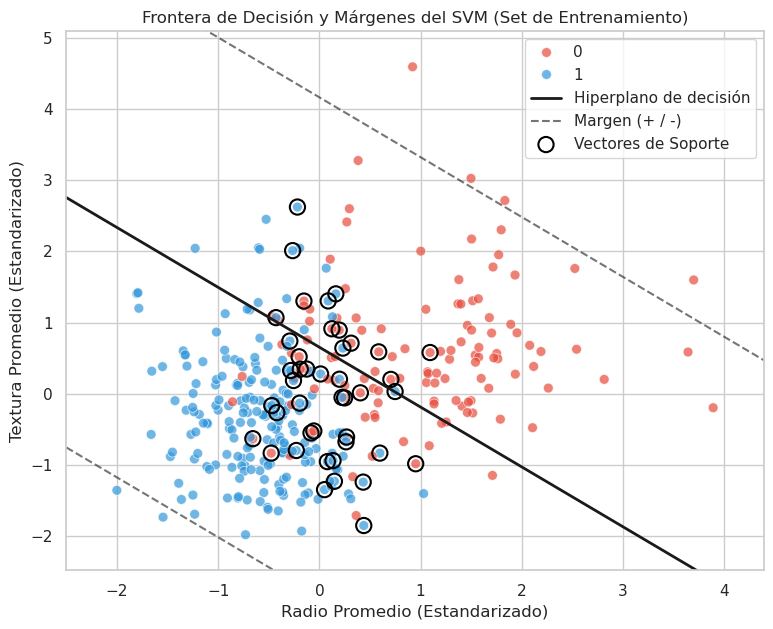

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_svm(modelo, X, y):
    # Función interna para calcular las líneas del hiperplano
    def get_hyperplane(x, w, b, offset):
        return (-w[0] * x - b + offset) / w[1]

    plt.figure(figsize=(9, 7))

    # 1. Graficamos los puntos usando tu paleta daltónica (Rojo y Azul)
    sns.scatterplot(
        x=X[:, 0], 
        y=X[:, 1], 
        hue=y, 
        palette={0: '#E74C3C', 1: '#3498DB'}, 
        alpha=0.7, 
        s=50
    )

    # Rango del eje X (Radio Promedio)
    x0_1 = np.amin(X[:, 0]) - 0.5
    x0_2 = np.amax(X[:, 0]) + 0.5
    xs = np.linspace(x0_1, x0_2, 100)

    # Extraemos pesos (w) e intercepto (b) del modelo lineal
    w = modelo.coef_[0]
    b = modelo.intercept_[0] if hasattr(modelo.intercept_, "__len__") else modelo.intercept_

    # 2. Trazamos las líneas del SVM
    plt.plot(xs, get_hyperplane(xs, w, b, 0), 'k-', linewidth=2, label='Hiperplano de decisión')    # Línea central
    plt.plot(xs, get_hyperplane(xs, w, b, 1), 'k--', alpha=0.6, label='Margen (+ / -)')          # Margen superior
    plt.plot(xs, get_hyperplane(xs, w, b, -1), 'k--', alpha=0.6)                                  # Margen inferior

    # 3. Resaltamos los Vectores de Soporte oficiales de Scikit-Learn
    # Dibujamos círculos negros vacíos alrededor de ellos
    support_v = modelo.support_vectors_
    plt.scatter(
        support_v[:, 0], 
        support_v[:, 1], 
        s=120, 
        linewidth=1.5, 
        facecolors='none', 
        edgecolors='black', 
        label='Vectores de Soporte'
    )

    # Ajustamos los límites visuales para que no se deforme el gráfico
    plt.xlim(x0_1, x0_2)
    plt.ylim(np.amin(X[:, 1]) - 0.5, np.amax(X[:, 1]) + 0.5)

    # Personalización de etiquetas
    plt.title("Frontera de Decisión y Márgenes del SVM (Set de Entrenamiento)")
    plt.xlabel("Radio Promedio (Estandarizado)")
    plt.ylabel("Textura Promedio (Estandarizado)")
    
    # Configuramos la leyenda mezclando tus clases y las líneas del SVM
    plt.legend(loc='upper right')
    plt.savefig('SVMmodel_tumores.png', dpi=300, bbox_inches='tight')
    plt.show()
visualize_svm(best_svm, X_train_scaled, y_train)

Observa la enorme distancia que hay entre las dos líneas punteadas (los márgenes). Al elegir un valor de penalización bajo ($C = 0.1$), el algoritmo priorizó un margen lo más amplio posible a cambio de permitir que varios puntos invadan la calle.Si hubiéramos elegido un $C$ muy alto (como $100$), el modelo habría intentado hacer la calle súper angosta para dejarla "limpia", lo cual habría provocado un sobreajuste (overfitting) severo al intentar esquivar de forma forzada los puntos mezclados en el centro. Este margen ancho garantiza que tu modelo sea robusto y generalice muy bien con datos nuevos.


### Validación Cruzada Anidada del SVM

In [22]:
# 1. Hacemos las predicciones finales con el SVM sobre el set de TESTEO
y_pred_test_svm = best_svm.predict(X_test_scaled)

# 2. Calculamos las métricas definitivas
accuracy_svm = accuracy_score(y_test, y_pred_test_svm)
bal_accuracy_svm = balanced_accuracy_score(y_test, y_pred_test_svm)

# Matriz de confusión y desglose
conf_matrix_svm = confusion_matrix(y_test, y_pred_test_svm)
TN_svm = conf_matrix_svm[0, 0]
FP_svm = conf_matrix_svm[0, 1]
FN_svm = conf_matrix_svm[1, 0]
TP_svm = conf_matrix_svm[1, 1]

# Especificidad: Verdaderos Benignos / Total Benignos Reales
specificity_svm = TP_svm / (TP_svm + FN_svm)

# Métricas enfocadas en la clase 0 (Malignos)
recall_maligno_svm = recall_score(y_test, y_pred_test_svm, pos_label=0)
f1_maligno_svm = f1_score(y_test, y_pred_test_svm, pos_label=0)
roc_auc_svm = roc_auc_score(y_test, best_svm.predict_proba(X_test_scaled)[:, 1])

# 3. Imprimimos el reporte final del SVM
print("=== VERDICTO FINAL: SVM OPTIMIZADO EN TESTEO ===")
print(f"Tasa de aciertos (Exactitud común): {accuracy_svm:.4f}")
print(f"Exactitud Balanceada: {bal_accuracy_svm:.4f}")
print(f"Sensibilidad (Malignos detectados): {recall_maligno_svm:.4f}")
print(f"Especificidad (Benignos detectados): {specificity_svm:.4f}")
print(f"F1 Score (Clase Maligna): {f1_maligno_svm:.4f}")
print(f"ROC AUC Score: {roc_auc_svm:.4f}")
print(f"\nConfusion Matrix:\n{conf_matrix_svm}")

=== VERDICTO FINAL: SVM OPTIMIZADO EN TESTEO ===
Tasa de aciertos (Exactitud común): 0.9825
Exactitud Balanceada: 0.9762
Sensibilidad (Malignos detectados): 0.9524
Especificidad (Benignos detectados): 1.0000
F1 Score (Clase Maligna): 0.9756
ROC AUC Score: 0.9960

Confusion Matrix:
[[40  2]
 [ 0 72]]


CONCLUSION SVM:
- SVM optimizado arrojó exactamente la misma matriz de confusión que la Regresión Logística ([[40, 2], [0, 72]]). Ambos modelos lograron identificar de manera idéntica a los 40 pacientes malignos y dejaron la especificidad intacta en un 100% (cero falsos positivos).
- Dieron similar por el kernel: El GridSearch del SVM eligió un kernel='linear'. Eso significa que ambos algoritmos estaban buscando exactamente lo mismo: trazar una línea recta ideal para separar los puntos rojos de los azules.


💡 Si queres saber qué modelo aplicar, podes repetir este proceso para diferentes modelo, y elegir en función de cuál te otorga mejores valores en validación y luego ver en testeo si eso se cumple :)


### MULTI-LAYER PERCEPTRON (REDES NEURONALES SIMPLES)                                          

Al introducir capas ocultas con funciones de activación no lineales (como relu o tanh), el MLP puede generar una frontera de decisión curva, sinuosa y ultrasutil, ideal para "esquivar" los puntos conflictivos y rodear con precisión quirúrgica esa zona difícil que vimos en tu gráfico.

MLPClassifier no tiene el parámetro class_weight='balanced'. Las redes neuronales  no traen ese truco de fábrica.
¿Cómo lo resolvemos? 

- Calcular los pesos de muestra manualmente (sample_weight): Le pasamos un vector al método .fit() para que penalice más los errores de la clase minoritaria.

- Optimizar mediante GridSearch: Dejamos que la arquitectura de la red y la regularización controlen el ajuste buscando maximizar tu métrica clave, el balanced_accuracy.

In [14]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, recall_score, f1_score, roc_auc_score

#Definimos grilla de hiperparametros para el MLP
# (10,): 1 capa oculta con 10 neuronas (modelo simple)
# (10, 5): 2 capas ocultas (una de 10 y otra de 5 neuronas, para buscar curvas complejas)
param_grid_mlp = {
    'hidden_layer_sizes': [(10,), (10, 5), (20,)],
    'activation': ['tanh', 'relu'],
    'alpha': [0.0001, 0.001, 0.01] # Regularización L2 para evitar que la curva se vuelva loca (overfitting)
}

#Iniciamos MLP
mlp_base = MLPClassifier(solver="lbfgs", max_iter=5000, random_state=120)

#Configuramos el GridsearchCV para datos desbalanceados
grid_search_mlp = GridSearchCV(
    estimator=mlp_base,
    param_grid=param_grid_mlp,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=-1
)

#Calculamos los pesos de las muestras para compensar el desbalance
pesos_entrenamiento = compute_sample_weight(class_weight = "balanced", y=y_train)
#Entrenamos el GridSearch con los pesos calculados
grid_search_mlp.fit(X_train_scaled, y_train, groups=None, **{'sample_weight': pesos_entrenamiento})

#Extraemos el mejor modelo que resulta del entrenamiento del GridsearchCV con pesos ponderados
best_mlp = grid_search_mlp.best_estimator_
print("=== RED NEURONAL ENTRENADA ===")
print(f"Mejores parámetros MLP: {grid_search_mlp.best_params_}\n")

=== RED NEURONAL ENTRENADA ===
Mejores parámetros MLP: {'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (10,)}



#Evaluacion en el conjunto de validacion

In [15]:
y_pred_val_mlp = best_mlp.predict(X_val_scaled)

# Métricas de performance
accuracy_mlp = accuracy_score(y_val, y_pred_val_mlp)
bal_accuracy_mlp = balanced_accuracy_score(y_val, y_pred_val_mlp)
conf_matrix_mlp = confusion_matrix(y_val, y_pred_val_mlp)
TN_mlp, FP_mlp, FN_mlp, TP_mlp = conf_matrix_mlp.ravel()
specificity_mlp = TP_mlp / (TP_mlp + FN_mlp)
recall_maligno_mlp = recall_score(y_val, y_pred_val_mlp, pos_label=0)
f1_maligno_mlp = f1_score(y_val, y_pred_val_mlp, pos_label=0)
roc_auc_mlp = roc_auc_score(y_val, best_mlp.predict_proba(X_val_scaled)[:, 1])

print("=== MÉTRICAS DEL MLP EN VALIDACIÓN ===")
print(f"Tasa de aciertos: {accuracy_mlp:.4f}")
print(f"Exactitud Balanceada: {bal_accuracy_mlp:.4f}  <-- Métrica objetivo")
print(f"Sensibilidad (Malignos): {recall_maligno_mlp:.4f}")
print(f"Especificidad (Benignos): {specificity_mlp:.4f}")
print(f"F1 Score (Malignos): {f1_maligno_mlp:.4f}")
print(f"ROC AUC Score: {roc_auc_mlp:.4f}")
print(f"\nConfusion Matrix:\n{conf_matrix_mlp}")

=== MÉTRICAS DEL MLP EN VALIDACIÓN ===
Tasa de aciertos: 0.9649
Exactitud Balanceada: 0.9581  <-- Métrica objetivo
Sensibilidad (Malignos): 0.9302
Especificidad (Benignos): 0.9859
F1 Score (Malignos): 0.9524
ROC AUC Score: 0.9597

Confusion Matrix:
[[40  3]
 [ 1 70]]


El GridSearch eligió una sola capa oculta con 10 neuronas hidden_layer_sizes: (10,) y una activación relu. Al tener un dataset con dos variables continuas bien distribuidas, la combinación de neuronas con activación ReLU (que son básicamente funciones lineales unidas por un vértice o "codo") terminó aproximando una frontera de decisión que actúa de forma casi idéntica a una línea recta. Descartó la arquitectura más compleja de dos capas (10, 5) porque no aportaba ninguna ventaja real.

Volvimos a chocar contra la pared de los 3 Falsos Negativos y 1 Falso Positivo. Esto nos confirma una sospecha teórica muy fuerte: esos 3 puntos malignos no están mal clasificados porque los modelos lineales sean "tontos" o rígidos; están ahí porque en la naturaleza real de tus datos

Evaluamos en el grupo de testeo

In [16]:
# 1. Hacemos las predicciones finales con el MLP sobre el set de TESTEO
y_pred_test_mlp = best_mlp.predict(X_test_scaled)

# 2. Calculamos las métricas definitivas en Testeo
accuracy_mlp_t = accuracy_score(y_test, y_pred_test_mlp)
bal_accuracy_mlp_t = balanced_accuracy_score(y_test, y_pred_test_mlp)

# Matriz de confusión y desglose manual
conf_matrix_mlp_t = confusion_matrix(y_test, y_pred_test_mlp)
TN_mlp_t, FP_mlp_t, FN_mlp_t, TP_mlp_t = conf_matrix_mlp_t.ravel()

# Especificidad: Verdaderos Benignos / Total Benignos Reales
specificity_mlp_t = TP_mlp_t / (TP_mlp_t + FN_mlp_t)

# Métricas enfocadas en la clase 0 (Malignos)
recall_maligno_mlp_t = recall_score(y_test, y_pred_test_mlp, pos_label=0)
f1_maligno_mlp_t = f1_score(y_test, y_pred_test_mlp, pos_label=0)
roc_auc_mlp_t = roc_auc_score(y_test, best_mlp.predict_proba(X_test_scaled)[:, 1])

# 3. Imprimimos el veredicto final del MLP
print("=== VERDICTO FINAL: MLP EN TESTEO ===")
print(f"Tasa de aciertos (Exactitud común): {accuracy_mlp_t:.4f}")
print(f"Exactitud Balanceada: {bal_accuracy_mlp_t:.4f}  <-- Métrica objetivo")
print(f"Sensibilidad (Malignos detectados): {recall_maligno_mlp_t:.4f}")
print(f"Especificidad (Benignos detectados): {specificity_mlp_t:.4f}")
print(f"F1 Score (Clase Maligna): {f1_maligno_mlp_t:.4f}")
print(f"ROC AUC Score: {roc_auc_mlp_t:.4f}")
print(f"\nConfusion Matrix:\n{conf_matrix_mlp_t}")

=== VERDICTO FINAL: MLP EN TESTEO ===
Tasa de aciertos (Exactitud común): 0.9649
Exactitud Balanceada: 0.9524  <-- Métrica objetivo
Sensibilidad (Malignos detectados): 0.9048
Especificidad (Benignos detectados): 1.0000
F1 Score (Clase Maligna): 0.9500
ROC AUC Score: 0.9940

Confusion Matrix:
[[38  4]
 [ 0 72]]


El MLP sufrió la falta de volumen: Las redes neuronales necesitan miles o millones de registros para mapear correctamente las sutilezas de los datos. En datasets de tamaño moderado o pequeño como este, la estructura rígida de un algoritmo lineal (SVM o Regresión Logística) siempre será superior y más estable que un Perceptrón

Si tuvieras que integrar esto en un sistema médico real hoy mismo, la Regresión Logística se lleva la medalla de oro. Te ofrece exactamente el mismo rendimiento óptimo que el SVM, pero con un costo computacional menor, mayor interpretabilidad para los médicos y la capacidad nativa de entregar una probabilidad del 0 al 100% en lugar de una clasificación binaria rígida.

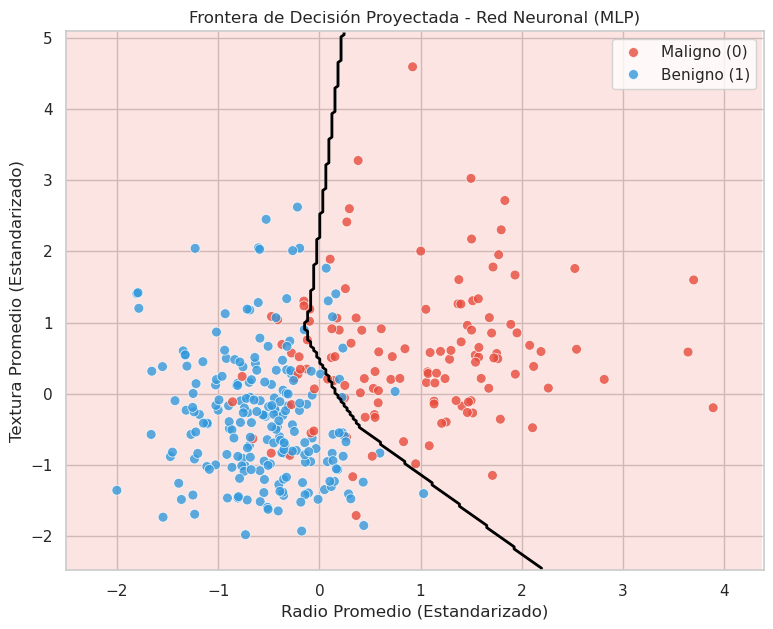

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_mlp_boundary_multidim(modelo, X_completo, y, feature_idx=[0, 1]):
    """
    Grafica la frontera de decisión para 2 variables manteniendo las demás constantes en su media.
    feature_idx: Lista con los índices de las dos variables que graficaremos (ej: [0, 1] para Radio y Textura)
    """
    plt.figure(figsize=(9, 7))
    
    idx_x, idx_y = feature_idx[0], feature_idx[1]
    
    # 1. Definir los límites basados en las dos variables elegidas
    x_min, x_max = X_completo[:, idx_x].min() - 0.5, X_completo[:, idx_x].max() + 0.5
    y_min, y_max = X_completo[:, idx_y].min() - 0.5, X_completo[:, idx_y].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.03),
                         np.arange(y_min, y_max, 0.03))
    
    # 2. CREAR EL TEMPLATE MULTIDIMENSIONAL
    # Calculamos la media de TODAS las 30 variables en el set de entrenamiento
    valores_medios = np.mean(X_completo, axis=0)
    
    # Repetimos esa fila promedio para cubrir cada punto de nuestra malla
    n_puntos_malla = xx.ravel().shape[0]
    malla_multidim = np.tile(valores_medios, (n_puntos_malla, 1))
    
    # Reemplazamos las columnas correspondientes al Radio y Textura con los valores de la malla
    malla_multidim[:, idx_x] = xx.ravel()
    malla_multidim[:, idx_y] = yy.ravel()
    
    # 3. Predecir usando la matriz con las 30 columnas completas
    Z = modelo.predict(malla_multidim)
    Z = Z.reshape(xx.shape)
    
    # 4. Pintar el fondo (Frontera de decisión proyectada)
    plt.contourf(xx, yy, Z, alpha=0.15, colors=['#E74C3C', '#3498DB'])
    plt.contour(xx, yy, Z, colors='black', corner_mask=True, linewidths=2, levels=[0.5])
    
    # 5. Graficar los puntos reales (usando solo las dos columnas del scatter original)
    sns.scatterplot(
        x=X_completo[:, idx_x], 
        y=X_completo[:, idx_y], 
        hue=y, 
        palette={0: '#E74C3C', 1: '#3498DB'}, 
        alpha=0.8, 
        s=50
    )
    
    # Personalización del gráfico
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title("Frontera de Decisión Proyectada - Red Neuronal (MLP)")
    plt.xlabel("Radio Promedio (Estandarizado)")
    plt.ylabel("Textura Promedio (Estandarizado)")
    
    handles, labels = plt.gca().get_legend_handles_labels()
    plt.legend(handles, ['Maligno (0)', 'Benigno (1)'], loc='upper right')
    
    plt.savefig('MLPmodel_tumores_multidim.png', dpi=300, bbox_inches='tight')
    plt.show()

# =====================================================================
# ¡Ejecutamos la nueva función pasándole la matriz completa de 30 columnas!
# =====================================================================
# Asumiendo que tus dos variables de interés están en las columnas 0 y 1
visualize_mlp_boundary_multidim(best_mlp, X_train_scaled, y_train, feature_idx=[0, 1])